# Workshop 3 · Part A · Steps 3–4 — Feature engineering and model training

Focus: a **reproducible scikit-learn `Pipeline`** (scaling + regressor) serialized as `models/model.pkl` and reused unchanged by the Kafka consumer. Model optimisation is deliberately out of scope.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from etl.harmonize import *
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160, "display.max_columns", 30)
import joblib
from etl.modeling import *

In [2]:
df = pd.read_csv(ROOT / 'data' / 'processed' / 'happiness_unified.csv')
print(df.shape)
df.head()

(782, 11)


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption,corruption_imputed
0,Afghanistan,Southern Asia,2015,3.575,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719,False
1,Albania,Central and Eastern Europe,2015,4.959,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413,False
2,Algeria,Middle East and Northern Africa,2015,5.605,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383,False
3,Angola,Sub-Saharan Africa,2015,4.033,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122,False
4,Argentina,Latin America and Caribbean,2015,6.574,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484,False


## 1. Feature selection and leakage check
**Target:** `happiness_score`.

**Features (6):** `gdp, family, health, freedom, generosity, corruption`.

Why these: they are the six Gallup explanatory factors, present in **every** year, numerical, and exactly the fields the streaming event contract carries — so the model can be served from the event alone.

Why **not** others:
- `happiness_rank`, `dystopia_residual`, standard error / CI / whiskers → derived from or describing the target (**leakage**) and absent in some years.
- `actual_happiness_score` in the event → used only to compute the error, never as input.
- `country` → 164 levels with at most 5 rows each: one-hot encoding would memorise countries instead of learning relationships.
- `year` → a time index the model cannot extrapolate from; the factors already capture the signal.
- `region` → not in the event contract; kept in `dim_country` for analytics.

The next cell proves the leakage claim on the raw 2015 file.

In [3]:
r15 = raw15 = pd.read_csv(ROOT / "data" / "raw" / "2015.csv")
parts = ["Economy (GDP per Capita)", "Family", "Health (Life Expectancy)", "Freedom",
         "Trust (Government Corruption)", "Generosity"]
resid = r15["Happiness Score"] - r15[parts].sum(axis=1) - r15["Dystopia Residual"]
print("max |score - (sum of 6 factors + dystopia residual)| in 2015:", resid.abs().max().round(5))
print("=> the residual completes the target (up to rounding), so including it would make the target trivially reconstructible.")

max |score - (sum of 6 factors + dystopia residual)| in 2015: 0.00051
=> the residual completes the target (up to rounding), so including it would make the target trivially reconstructible.


In [4]:
corr = df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
corr.round(3).to_frame("pearson r with happiness_score")

,pearson r with happiness_score
gdp,0.789
health,0.742
family,0.649
freedom,0.551
corruption,0.400
generosity,0.138


## 2. Categorical data and scaling
All six features are numeric, so **no encoding is needed**. Their scales differ (gdp up to 2.1, corruption up to 0.55), so a `StandardScaler` is included **inside the Pipeline**: it is fitted on the training split only (no test-set leakage) and is applied identically at inference time inside the consumer.

## 3. Train / test split (70 / 30)

In [5]:
X_tr, X_te, y_tr, y_te, test_df = split(df)
print("train", X_tr.shape, "test", X_te.shape)
print("feature order:", list(X_tr.columns))

train (547, 6) test (235, 6)
feature order: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


## 4. Train and compare simple regressors

In [6]:
rows, fitted = [], {}
for name, pipe in candidates().items():
    pipe.fit(X_tr, y_tr); fitted[name] = pipe
    for part, X, y in (("train", X_tr, y_tr), ("test", X_te, y_te)):
        rows.append({"model": name, "split": part, **evaluate(pipe, X, y)})
results = pd.DataFrame(rows).pivot(index="model", columns="split").round(4)
results

MAE            RMSE              R2        
split                test   train    test   train    test   train
model                                                            
decision_tree      0.4701  0.3458  0.6049  0.4424  0.7136  0.8452
linear_regression  0.4289  0.4245  0.5538  0.5454  0.7599  0.7647
random_forest      0.3944  0.1399  0.5025  0.1844  0.8024  0.9731

**Decision:** Random forest scores a little better, but the workshop's goal is pipeline integration, not accuracy. We ship **Linear Regression**: no tuning, fully reproducible, interpretable coefficients and a ~2 KB pickle. It explains ~76% of the variance on unseen rows (MAE ≈ 0.43 on a 3–8 scale). Swapping the estimator later only requires changing `chosen`.

In [7]:
chosen = "linear_regression"
pipe = fitted[chosen]
coefs = pd.Series(pipe.named_steps["model"].coef_, index=FEATURES).sort_values(ascending=False)
coefs.round(3).to_frame("standardized coefficient")

,standardized coefficient
gdp,0.474
health,0.240
family,0.222
freedom,0.205
corruption,0.111
generosity,0.070


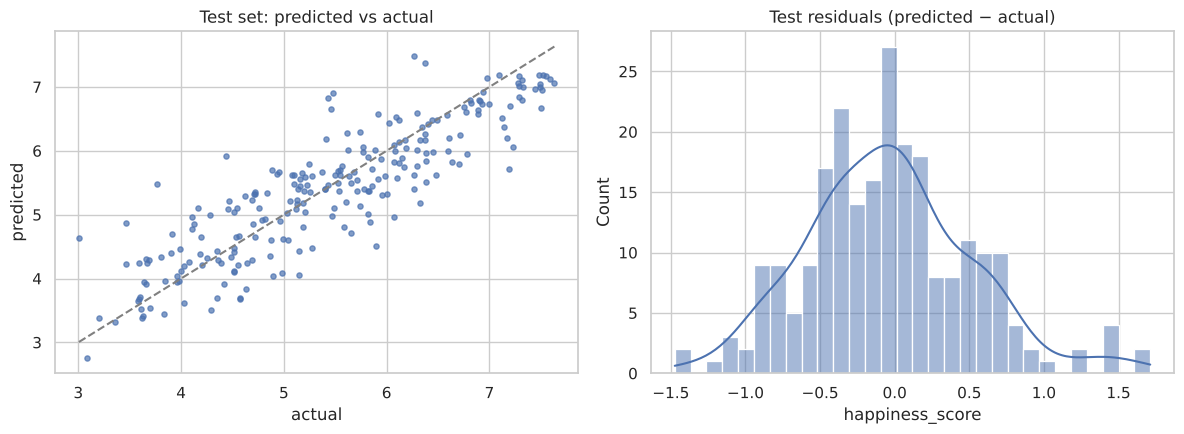

In [8]:
pred = pipe.predict(X_te)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_te, pred, s=14, alpha=.7); lo, hi = y_te.min(), y_te.max()
axes[0].plot([lo, hi], [lo, hi], "--", color="grey"); axes[0].set_xlabel("actual"); axes[0].set_ylabel("predicted")
axes[0].set_title("Test set: predicted vs actual")
sns.histplot(pred - y_te, bins=30, kde=True, ax=axes[1]); axes[1].set_title("Test residuals (predicted − actual)")
plt.tight_layout()

In [9]:
# Robustness check (not used for the final model): hold out entire COUNTRIES instead of random rows
from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone
g_tr, g_te = next(GroupShuffleSplit(test_size=0.3, random_state=RANDOM_STATE).split(df, groups=df["country"]))
p = clone(candidates()[chosen]).fit(df.iloc[g_tr][FEATURES], df.iloc[g_tr][TARGET])
print("Country-grouped holdout:", {k: round(v, 3) for k, v in evaluate(p, df.iloc[g_te][FEATURES], df.iloc[g_te][TARGET]).items()})
print("Random-row holdout     :", {k: round(v, 3) for k, v in evaluate(pipe, X_te, y_te).items()})

Country-grouped holdout: {'MAE': 0.432, 'RMSE': 0.562, 'R2': 0.784}
Random-row holdout     : {'MAE': 0.429, 'RMSE': 0.554, 'R2': 0.76}


The country-grouped holdout (a different test set) scores about the same (R² ≈ 0.78 vs 0.76), so the same country appearing in train and test does not appear to be inflating the score.

## 5. Serialize the pipeline and the streaming set

In [10]:
metrics = evaluate(pipe, X_te, y_te)
path = save_model(pipe, chosen, metrics, ROOT / "models")
print("saved", path)
print(json.dumps(json.loads((ROOT / "models" / "model_metadata.json").read_text()), indent=2))

saved /home/claude/project/models/model.pkl
{
  "model_name": "linear_regression",
  "model_version": "20261110010212",
  "features": [
    "gdp",
    "family",
    "health",
    "freedom",
    "generosity",
    "corruption"
  ],
  "target": "happiness_score",
  "test_size": 0.3,
  "random_state": 42,
  "metrics_test": {
    "MAE": 0.4288855734565174,
    "RMSE": 0.5538384469985669,
    "R2": 0.7599169846867255
  }
}


In [11]:
# Sanity: reload and confirm feature names/order and identical predictions
loaded = joblib.load(path)
assert list(loaded.feature_names_in_) == FEATURES
assert np.allclose(loaded.predict(X_te), pred)
print("reloaded model OK; expects:", list(loaded.feature_names_in_))

reloaded model OK; expects: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


In [12]:
stream = ROOT / "data" / "streaming"; stream.mkdir(parents=True, exist_ok=True)
test_df.sort_values(["year", "country"]).to_csv(stream / "stream_test.csv", index=False)
print(len(test_df), "held-out rows saved for the Kafka producer ->", stream / "stream_test.csv")

235 held-out rows saved for the Kafka producer -> /home/claude/project/data/streaming/stream_test.csv


## 6. Evaluation summary
See the table in §4. Final model (**Linear Regression**, test split): MAE ≈ 0.429 · RMSE ≈ 0.554 · R² ≈ 0.760.